In [22]:

import re
import calendar
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import geopandas as gpd

PROJECT_DIR = Path.cwd()

WIKI_INTERIM_DIR = (
    PROJECT_DIR / "data" / "interim" / "wikipedia_earthquake_list"
)

month_numbers = {
    month: number
    for number, month in enumerate(calendar.month_name)
    if month
}

# Match only monthly tables, excluding By_death_toll and By_magnitude
month_pattern = re.compile(
    r"^(January|February|March|April|May|June|"
    r"July|August|September|October|November|December)"
    r"_(\d{4})(?:_part\d+)?$",
    flags=re.IGNORECASE
)

monthly_files = []

for year_dir in sorted(WIKI_INTERIM_DIR.glob("earthquakes_*")):

    folder_match = re.fullmatch(
        r"earthquakes_(\d{4})",
        year_dir.name
    )

    if not folder_match:
        continue

    folder_year = int(folder_match.group(1))

    for file_path in sorted(year_dir.glob("*.csv")):

        match = month_pattern.fullmatch(file_path.stem)

        if not match:
            continue

        month_name = match.group(1).capitalize()
        file_year = int(match.group(2))

        if file_year != folder_year:
            continue

        monthly_files.append({
            "path": file_path,
            "year": file_year,
            "month": month_name,
            "month_number": month_numbers[month_name]
        })

# Create file inventory
file_inventory = []

for item in monthly_files:

    temp = pd.read_csv(
        item["path"],
        keep_default_na=False,
        encoding="utf-8-sig"
    )

    file_inventory.append({
        "year": item["year"],
        "month": item["month"],
        "month_number": item["month_number"],
        "filename": item["path"].name,
        "rows": len(temp),
        "columns": ", ".join(temp.columns.astype(str))
    })

monthly_inventory = pd.DataFrame(file_inventory)

print("Total monthly files:", len(monthly_files))
print("Expected monthly files:", 26 * 12)

print(
    "Years covered:",
    sorted(monthly_inventory["year"].unique())
    if not monthly_inventory.empty else []
)

print("\nMonthly file inventory:")
display(monthly_inventory)

# Check missing months
expected_months = {
    (year, month)
    for year in range(2000, 2026)
    for month in range(1, 13)
}

available_months = {
    (item["year"], item["month_number"])
    for item in monthly_files
}

missing_months = sorted(expected_months - available_months)

print("\nMissing monthly files:", len(missing_months))
display(pd.DataFrame(
    missing_months,
    columns=["year", "month_number"]
))


Total monthly files: 309
Expected monthly files: 312
Years covered: [np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

Monthly file inventory:


,year,month,month_number,filename,rows,columns
0,2000,April,4,April_2000.csv,9,"year, Date, Country and location, Mw, Depth (k..."
1,2000,August,8,August_2000.csv,19,"year, Date, Country and location, Mw, Depth (k..."
2,2000,December,12,December_2000.csv,16,"year, Date, Country and location, Mw, Depth (k..."
3,2000,February,2,February_2000.csv,12,"year, Date, Country and location, Mw, Depth (k..."
4,2000,January,1,January_2000.csv,21,"year, Date, Country and location, Mw, Depth (k..."
...,...,...,...,...,...,...
304,2025,March,3,March_2025.csv,31,"year, Date, Country and location, Mw, Depth (k..."
305,2025,May,5,May_2025.csv,34,"year, Date, Country and location, Mw, Depth (k..."
306,2025,November,11,November_2025.csv,23,"year, Date, Country and location, Mw, Depth (k..."
307,2025,October,10,October_2025.csv,29,"year, Date, Country and location, Mw, Depth (k..."



Missing monthly files: 3


,year,month_number
0,2008,10
1,2008,11
2,2008,12


In [23]:
# Inspect all files available for 2008

year_2008_dir = WIKI_INTERIM_DIR / "earthquakes_2008"

files_2008 = sorted(year_2008_dir.glob("*.csv"))

print("Files available for 2008:")
display(pd.DataFrame({
    "filename": [f.name for f in files_2008],
    "size_kb": [round(f.stat().st_size / 1024, 2) for f in files_2008]
}))

# Inspect the annual death-toll table
death_toll_path = year_2008_dir / "By_death_toll_2008.csv"

if death_toll_path.exists():
    df_death_toll_2008 = pd.read_csv(death_toll_path)

    print("\nDeath-toll table shape:", df_death_toll_2008.shape)
    print("\nColumns:")
    print(df_death_toll_2008.columns.tolist())

    display(df_death_toll_2008.head(20))
else:
    print("\nBy_death_toll_2008.csv not found.")

Files available for 2008:


,filename,size_kb
0,April_2008.csv,0.93
1,August_2008.csv,0.83
2,By_death_toll_2008.csv,0.63
3,By_magnitude_2008.csv,0.87
4,February_2008.csv,0.77
5,January_2008.csv,0.88
6,July_2008.csv,0.48
7,June_2008.csv,0.37
8,March_2008.csv,0.79
9,May_2008.csv,0.45



Death-toll table shape: (9, 8)

Columns:
['year', 'Rank', 'Death toll', 'Magnitude', 'Location', 'MMI', 'Depth (km)', 'Date']


,year,Rank,Death toll,Magnitude,Location,MMI,Depth (km),Date
0,2008,1,"87,587",7.9,"China, Sichuan",XI (Extreme),19.0,May 12
1,2008,2,215,6.4,"Pakistan, Balochistan",VIII (Severe),10.0,October 29
2,2008,3,75,6.6,"Kyrgyzstan, Osh",VII (Very strong),27.6,October 5
3,2008,4,44,5.9,"DR Congo, Lake Kivu",VIII (Severe),10.0,February 3
4,2008,5,41,6.1,"China, Sichuan",VI (Strong),10.0,August 30
5,2008,6,23,6.9,"Japan, Honshu",IX (Violent),8.0,June 13
6,2008,7,13,5.8,"Russia, Dagestan",VII (Very strong),20.0,October 11
7,2008,8,11,5.9,"Colombia, El Calvario",VII (Very strong),35.0,May 24
8,2008,9,10,6.4,"China, Tibet",VII (Very strong),10.0,October 6


In [24]:
monthly_files = []
ranking_files = []

monthly_pattern = re.compile(
    r"^(January|February|March|April|May|June|July|August|"
    r"September|October|November|December)"
    r"_(\d{4})(?:_part\d+)?$",
    flags=re.IGNORECASE
)

ranking_pattern = re.compile(
    r"^By_(death_toll|magnitude)_(\d{4})$",
    flags=re.IGNORECASE
)

for year_dir in sorted(WIKI_INTERIM_DIR.glob("earthquakes_*")):

    if not year_dir.is_dir():
        continue

    folder_year = int(year_dir.name.split("_")[-1])

    for file_path in sorted(year_dir.glob("*.csv")):

        monthly_match = monthly_pattern.fullmatch(file_path.stem)
        ranking_match = ranking_pattern.fullmatch(file_path.stem)

        if monthly_match:
            month_name = monthly_match.group(1).capitalize()
            year = int(monthly_match.group(2))

            if year == folder_year:
                monthly_files.append({
                    "path": file_path,
                    "year": year,
                    "month": month_name,
                    "month_number": month_numbers[month_name]
                })

        elif ranking_match:
            ranking_type = ranking_match.group(1).lower()
            year = int(ranking_match.group(2))

            if year == folder_year:
                ranking_files.append({
                    "path": file_path,
                    "year": year,
                    "type": ranking_type
                })

        # All other CSV files are deliberately ignored.

print("Monthly files:", len(monthly_files))
print("Death-toll files:", sum(
    f["type"] == "death_toll" for f in ranking_files
))
print("Magnitude files:", sum(
    f["type"] == "magnitude" for f in ranking_files
))

print("Excluded files: Number_of_earthquakes_worldwide and others.")

Monthly files: 309
Death-toll files: 26
Magnitude files: 26
Excluded files: Number_of_earthquakes_worldwide and others.


In [25]:
from datetime import datetime
from dateutil import parser as date_parser

def parse_ranking_date(value, year):

    if pd.isna(value) or not str(value).strip():
        return pd.NaT

    date_text = str(value).strip()

    date_text = re.sub(r"\[[^\]]*\]", "", date_text)
    date_text = re.sub(
        r"(\d+)(st|nd|rd|th)\b",
        r"\1",
        date_text,
        flags=re.IGNORECASE
    )

    try:
        parsed = date_parser.parse(
            date_text,
            default=datetime(int(year), 1, 1),
            dayfirst=True,
            fuzzy=False
        )

        # Reject dates whose explicit year conflicts
        # with the year column.
        if parsed.year != int(year):
            return pd.NaT

        return pd.Timestamp(parsed)

    except (ValueError, TypeError, OverflowError):
        return pd.NaT

In [26]:
# Inspect original February 2023 casualty records

FEB_2023_PATH = (
    WIKI_INTERIM_DIR
    / "earthquakes_2023"
    / "February_2023.csv"
)

raw_feb_2023 = pd.read_csv(
    FEB_2023_PATH,
    dtype=str,
    keep_default_na=False,
    encoding="utf-8-sig"
)

raw_feb_2023

,year,Date,Country and location,Mw,Depth (km),MMI,Notes,Casualties Dead,Casualties Injured
0,2023,1,"Philippines, Davao, 2 km (1.2 mi) northwest of...",6.0,19.0,VII,Sixteen people injured; eight houses collapsed...,-,16
1,2023,1,"Indonesia, West Java, 24 km (15 mi) east south...",4.5,10.0,III,One person injured; 495 houses and eight schoo...,-,1
2,2023,4,"Iran, Kermanshah, 19 km (12 mi) southwest of S...",4.7,10.0,V,Four people injured due to panic in Qasr-e Shi...,-,4
3,2023,6,"Turkey, Kahramanmaraş, 26 km (16 mi) east of N...",7.8,10.0,XII,Further information: 2023 Turkey–Syria earthqu...,"59,488–62,013","121,704"
4,2023,6,"Turkey, Gaziantep, 18 km (11 mi) east southeas...",6.7,9.8,VIII,Further information: 2023 Turkey–Syria earthqu...,"59,488–62,013","121,704"
5,2023,6,"Turkey, Kahramanmaraş, 4 km (2.5 mi) south sou...",7.5,7.4,XI,Further information: 2023 Turkey–Syria earthqu...,"59,488–62,013","121,704"
6,2023,6,"Turkey, Malatya, 10 km (6.2 mi) southeast of D...",6.0,20.1,VII,Further information: 2023 Turkey–Syria earthqu...,"59,488–62,013","121,704"
7,2023,6,"Turkey, Kahramanmaraş, 5 km (3.1 mi) northeast...",6.0,8.5,VIII,Further information: 2023 Turkey–Syria earthqu...,"59,488–62,013","121,704"
8,2023,7,"Philippines, Bicol offshore, 20 km (12 mi) nor...",4.8,10.0,IV,Twenty-one buildings and two houses damaged in...,-,-
9,2023,8,"Peru, Huancavelica, 15 km (9.3 mi) west southw...",3.4,10.0,-,Seventy houses and a church damaged in Huasica...,-,-


In [27]:
raw_feb_2023.dtypes

year                    str
Date                    str
Country and location    str
Mw                      str
Depth (km)              str
MMI                     str
Notes                   str
Casualties Dead         str
Casualties Injured      str
dtype: object

In [28]:

# ==========================================
# RAW WIKIPEDIA DATA: LOAD AND PROFILE
# ==========================================

raw_file_specs = []

# Monthly earthquake files
for item in monthly_files:
    raw_file_specs.append({
        "path": item["path"],
        "year": item["year"],
        "source_type": "monthly"
    })

# Annual ranking files
for item in ranking_files:
    raw_file_specs.append({
        "path": item["path"],
        "year": item["year"],
        "source_type": item["type"]
    })


# Load without applying any cleaning or standardisation
raw_wiki_tables = {}
file_inventory = []
column_profiles = []

for item in raw_file_specs:

    path = item["path"]

    try:
        raw = pd.read_csv(
            path,
            encoding="utf-8-sig",
            low_memory=False
        )
    except pd.errors.EmptyDataError:
        print(f"Empty file: {path.name}")
        continue

    file_id = str(path)

    # Retain original dataframe for future inspection
    raw_wiki_tables[file_id] = raw

    file_inventory.append({
        "year": item["year"],
        "source_type": item["source_type"],
        "filename": path.name,
        "rows": len(raw),
        "columns": len(raw.columns),
        "column_names": list(raw.columns)
    })

    # Profile individual columns
    for col in raw.columns:

        series = raw[col]

        # Detect actual missing values and whitespace-only values
        blank_mask = (
            series.astype("string")
            .str.strip()
            .eq("")
            .fillna(False)
        )

        missing_mask = series.isna() | blank_mask

        # Track dash placeholders separately
        dash_mask = (
            series.astype("string")
            .str.strip()
            .isin(["-", "—", "–"])
            .fillna(False)
        )

        column_profiles.append({
            "file_id": file_id,
            "year": item["year"],
            "source_type": item["source_type"],
            "filename": path.name,
            "column": col,
            "dtype": str(series.dtype),
            "row_count": len(raw),
            "missing_count": int(missing_mask.sum()),
            "missing_percentage": (
                missing_mask.mean() * 100
                if len(raw) else 0
            ),
            "unique_values": series[~missing_mask].nunique(),
            "dash_placeholders": int(dash_mask.sum())
        })


raw_inventory = pd.DataFrame(file_inventory)
raw_profile = pd.DataFrame(column_profiles)

print("RAW WIKIPEDIA DATA LOADING COMPLETE")
print("Files loaded:", len(raw_wiki_tables))
print("Total rows across source files:",
      raw_inventory["rows"].sum())

print("\nFiles by source type:")
display(
    raw_inventory.groupby("source_type")
    .agg(
        files=("filename", "count"),
        total_rows=("rows", "sum"),
        unique_years=("year", "nunique")
    )
)


RAW WIKIPEDIA DATA LOADING COMPLETE
Files loaded: 361
Total rows across source files: 5912

Files by source type:


,files,total_rows,unique_years
source_type,,,
death_toll,26,194,26
magnitude,26,399,26
monthly,309,5319,26


In [29]:

dtype_summary = (
    raw_profile.groupby(
        ["source_type", "column", "dtype"]
    )
    .agg(
        files=("file_id", "nunique"),
        total_rows=("row_count", "sum")
    )
    .reset_index()
    .sort_values(["source_type", "column"])
)

display(dtype_summary)


,source_type,column,dtype,files,total_rows
0,death_toll,Date,str,26,194
1,death_toll,Death toll,float64,4,21
2,death_toll,Death toll,int64,6,43
3,death_toll,Death toll,str,15,122
4,death_toll,Death toll,str,1,8
5,death_toll,Depth (km),float64,26,194
6,death_toll,Event,str,12,93
7,death_toll,Location,str,26,194
8,death_toll,MMI,str,26,194
9,death_toll,Magnitude,float64,26,194


In [30]:

dtype_consistency = (
    raw_profile.groupby(["source_type", "column"])
    .agg(
        number_of_dtypes=("dtype", "nunique"),
        observed_dtypes=(
            "dtype",
            lambda x: ", ".join(sorted(x.unique()))
        ),
        files=("file_id", "nunique")
    )
    .reset_index()
)

inconsistent_columns = dtype_consistency[
    dtype_consistency["number_of_dtypes"] > 1
]

inconsistent_columns


,source_type,column,number_of_dtypes,observed_dtypes,files
1,death_toll,Death toll,3,"float64, int64, str",25
8,death_toll,Rank,2,"float64, int64",26
11,magnitude,Death toll,3,"float64, int64, str",25
19,magnitude,Rank,2,"float64, int64",26
22,monthly,Casualties Dead,2,"float64, str",306
23,monthly,Casualties Injured,2,"float64, str",306
28,monthly,Date,3,"float64, int64, str",308
30,monthly,Depth (km),3,"float64, int64, str",309
32,monthly,Mw,2,"float64, str",309
34,monthly,column,2,"float64, str",4


In [31]:

missing_summary = (
    raw_profile.groupby(["source_type", "column"])
    .agg(
        files=("file_id", "nunique"),
        total_rows=("row_count", "sum"),
        missing_count=("missing_count", "sum"),
        dash_placeholders=("dash_placeholders", "sum")
    )
    .reset_index()
)

missing_summary["missing_percentage"] = (
    missing_summary["missing_count"]
    / missing_summary["total_rows"] * 100
)

missing_summary["available_count"] = (
    missing_summary["total_rows"]
    - missing_summary["missing_count"]
)

missing_summary = missing_summary.sort_values(
    ["source_type", "missing_percentage"],
    ascending=[True, False]
)

display(missing_summary.round(2))


,source_type,column,files,total_rows,missing_count,dash_placeholders,missing_percentage,available_count
2,death_toll,Death toll,1,8,1,0,12.50,7
4,death_toll,Event,12,93,9,2,9.68,84
0,death_toll,Date,26,194,11,0,5.67,183
3,death_toll,Depth (km),26,194,11,0,5.67,183
5,death_toll,Location,26,194,11,0,5.67,183
6,death_toll,MMI,26,194,11,0,5.67,183
7,death_toll,Magnitude,26,194,11,0,5.67,183
8,death_toll,Rank,26,194,11,0,5.67,183
1,death_toll,Death toll,25,186,10,0,5.38,176
9,death_toll,year,26,194,0,0,0.00,194


In [32]:

missing_by_year = (
    raw_profile.groupby(
        ["year", "source_type", "column"]
    )
    .agg(
        rows=("row_count", "sum"),
        missing=("missing_count", "sum")
    )
    .reset_index()
)

missing_by_year["missing_percentage"] = (
    missing_by_year["missing"]
    / missing_by_year["rows"] * 100
)

display(
    missing_by_year.sort_values(
        ["source_type", "column", "year"]
    ).round(2)
)


,year,source_type,column,rows,missing,missing_percentage
0,2000,death_toll,Date,5,1,20.00
27,2001,death_toll,Date,4,0,0.00
52,2002,death_toll,Date,11,1,9.09
87,2003,death_toll,Date,9,1,11.11
114,2004,death_toll,Date,11,1,9.09
...,...,...,...,...,...,...
571,2021,monthly,year,294,0,0.00
598,2022,monthly,year,281,0,0.00
625,2023,monthly,year,303,0,0.00
652,2024,monthly,year,207,0,0.00


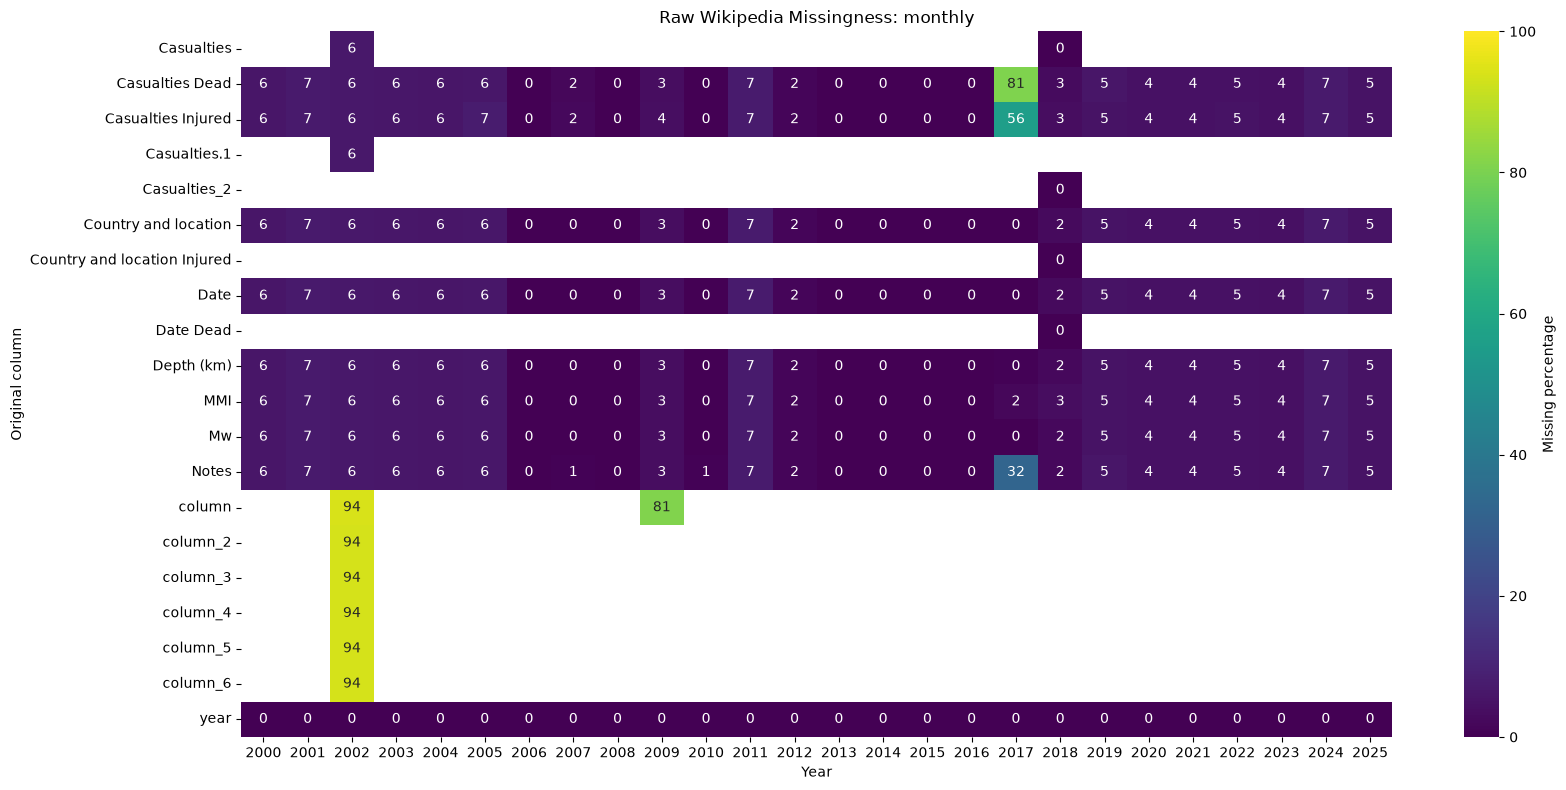

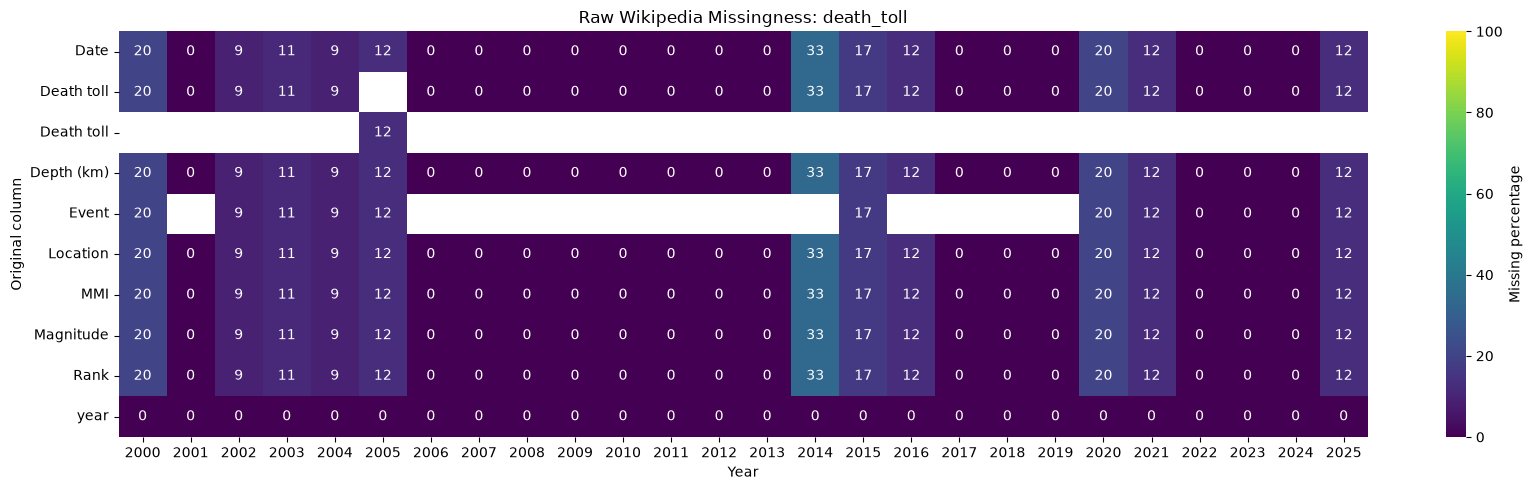

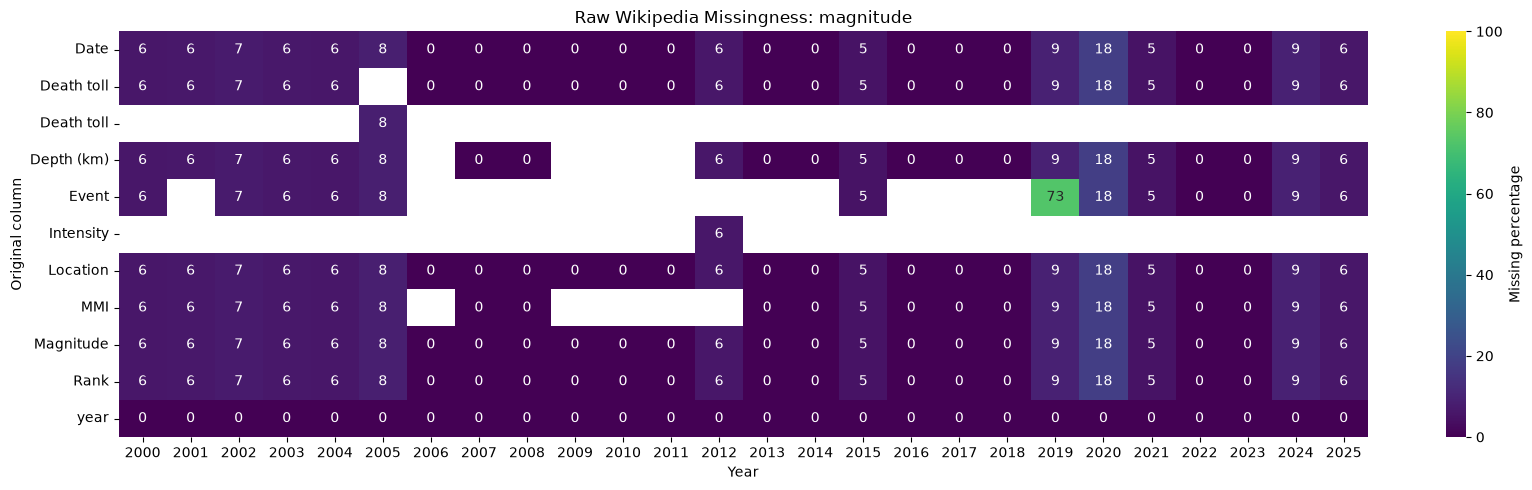

In [33]:
import matplotlib.pyplot as plt

for source in ["monthly", "death_toll", "magnitude"]:

    subset = missing_by_year[
        missing_by_year["source_type"] == source
    ]

    pivot = subset.pivot(
        index="column",
        columns="year",
        values="missing_percentage"
    )

    if pivot.empty:
        continue

    plt.figure(figsize=(17, max(5, len(pivot) * 0.4)))

    sns.heatmap(
        pivot,
        cmap="viridis",
        vmin=0,
        vmax=100,
        annot=True,
        fmt=".0f",
        mask=pivot.isna(),
        cbar_kws={"label": "Missing percentage"}
    )

    plt.title(f"Raw Wikipedia Missingness: {source}")
    plt.xlabel("Year")
    plt.ylabel("Original column")
    plt.tight_layout()
    plt.show()


In [34]:

# Inspect original 2008 death-toll table

path_2008 = (
    WIKI_INTERIM_DIR
    / "earthquakes_2008"
    / "By_death_toll_2008.csv"
)

df_raw_2008 = raw_wiki_tables[str(path_2008)]

print(df_raw_2008.info())
display(df_raw_2008.head(10))


<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   year        9 non-null      int64  
 1   Rank        9 non-null      int64  
 2   Death toll  9 non-null      str    
 3   Magnitude   9 non-null      float64
 4   Location    9 non-null      str    
 5   MMI         9 non-null      str    
 6   Depth (km)  9 non-null      float64
 7   Date        9 non-null      str    
dtypes: float64(2), int64(2), str(4)
memory usage: 1.1 KB
None


,year,Rank,Death toll,Magnitude,Location,MMI,Depth (km),Date
0,2008,1,"87,587",7.9,"China, Sichuan",XI (Extreme),19.0,May 12
1,2008,2,215,6.4,"Pakistan, Balochistan",VIII (Severe),10.0,October 29
2,2008,3,75,6.6,"Kyrgyzstan, Osh",VII (Very strong),27.6,October 5
3,2008,4,44,5.9,"DR Congo, Lake Kivu",VIII (Severe),10.0,February 3
4,2008,5,41,6.1,"China, Sichuan",VI (Strong),10.0,August 30
5,2008,6,23,6.9,"Japan, Honshu",IX (Violent),8.0,June 13
6,2008,7,13,5.8,"Russia, Dagestan",VII (Very strong),20.0,October 11
7,2008,8,11,5.9,"Colombia, El Calvario",VII (Very strong),35.0,May 24
8,2008,9,10,6.4,"China, Tibet",VII (Very strong),10.0,October 6


In [35]:

# ==============================================
# CELL 1: REUSABLE METHODS
# ==============================================

import re
import calendar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


MONTH_NAMES = list(calendar.month_name)[1:]

MISSING_TEXT = {
    "", "-", "--", "—", "–",
    "na", "n/a", "nan", "none",
    "null", "unknown", "not reported",
    "not known"
}


# Columns expected to contain numeric information
NUMERIC_COLUMN_NAMES = {
    "deathtoll",
    "casualtiesdead",
    "casualtiesinjured",
    "rank",
    "mw",
    "magnitude",
    "depth",
    "depthkm",
    "deaths",
    "dead",
    "injuries",
    "injured",
    "wounded"
}


# ==============================================
# GENERAL CLEANING METHODS
# ==============================================

def normalise_column(col):
    """Normalise column names for comparison."""

    return re.sub(r"[^a-z0-9]", "", str(col).lower())


def is_missing_value(value):
    """Identify actual missing values and common placeholders."""

    if pd.isna(value):
        return True

    return str(value).strip().lower() in MISSING_TEXT


def is_numeric_candidate(col):
    """Check whether a column is expected to contain numeric data."""

    return normalise_column(col) in NUMERIC_COLUMN_NAMES


# ==============================================
# NUMERIC VALUE PREPARATION
# ==============================================

def prepare_numeric_text(value):
    """
    Prepare raw numeric text.

    Handles:
    - Thousands separators
    - Wikipedia citations
    - Approximate prefixes
    - Unicode minus signs
    - Missing placeholders
    """

    if is_missing_value(value):
        return None

    text = str(value).strip()

    # Remove Wikipedia reference markers
    text = re.sub(r"\[[^\]]*\]", "", text).strip()

    if text.lower() in MISSING_TEXT:
        return None

    # Remove thousands separators
    text = text.replace(",", "")

    # Normalise Unicode minus
    text = text.replace("−", "-")

    # Remove approximate prefixes
    text = re.sub(
        r"^(?:~|≈|about\b|approximately\b|approx\.?\b|c\.\s*)\s*",
        "",
        text,
        flags=re.IGNORECASE
    )

    return text.strip()


# ==============================================
# NUMERIC PATTERNS
# ==============================================

NUM_PATTERN = r"[+-]?(?:\d+(?:\.\d*)?|\.\d+)"

# Examples: 500-700, 500–700, 500—700, 500 to 700
RANGE_PATTERN = re.compile(
    rf"^\s*({NUM_PATTERN})\s*(?:-|–|—|to)\s*({NUM_PATTERN})\s*$",
    flags=re.IGNORECASE
)

# Examples: 500+, 1000+, 250 +
PLUS_PATTERN = re.compile(
    rf"^\s*({NUM_PATTERN})\s*\+\s*$"
)

# Examples: 500, 7.8, -2.5
SINGLE_NUMBER_PATTERN = re.compile(
    rf"^\s*{NUM_PATTERN}\s*$"
)

# Extract numerical tokens from otherwise unrecognized text
NUMBER_SEARCH_PATTERN = re.compile(
    rf"(?<![\w.]){NUM_PATTERN}(?![\w.])"
)


# ==============================================
# NUMERIC CLASSIFICATION
# ==============================================

def classify_numeric_value(value):
    """
    Classify raw numeric representations.

    Returns:
        numeric:
            Exact numeric value.

        range_upper:
            Range converted to its upper endpoint.

        lower_bound:
            Plus notation converted to its stated value.

        extracted_number:
            A single number extracted from unrecognized text.

        missing:
            Missing value or placeholder.

        unparsed:
            No number or multiple ambiguous numbers.
    """

    text = prepare_numeric_text(value)

    if text is None:
        return "missing", np.nan

    # 1. Range handling
    match = RANGE_PATTERN.fullmatch(text)

    if match:
        lower = float(match.group(1))
        upper = float(match.group(2))

        return "range_upper", max(lower, upper)

    # 2. Plus notation handling
    match = PLUS_PATTERN.fullmatch(text)

    if match:
        return "lower_bound", float(match.group(1))

    # 3. Exact numeric values
    if SINGLE_NUMBER_PATTERN.fullmatch(text):
        return "numeric", float(text)

    # 4. Extract a single number from unrecognized text
    numbers = NUMBER_SEARCH_PATTERN.findall(text)

    if len(numbers) == 1:
        return "extracted_number", float(numbers[0])

    # 5. Multiple numbers or no numerical content
    return "unparsed", np.nan


# ==============================================
# NUMERIC CONVERSION
# ==============================================

def parse_numeric_upper(value):
    """
    Convert numeric representations into numeric proxies.

    Exact value       -> Same value
    Range             -> Upper endpoint
    Plus notation     -> Stated lower bound
    Extracted number  -> Extracted numerical value
    Missing           -> NaN
    Unparsed          -> NaN

    Classification is retained separately using
    classify_numeric_value().
    """

    kind, number = classify_numeric_value(value)

    if kind in {
        "numeric",
        "range_upper",
        "lower_bound",
        "extracted_number"
    }:
        return number

    return np.nan


In [36]:
test_values = [
    "59,259–62,013",
    "500+",
    "1,000 +",
    "7.8",
    "~7.8",
    "7.8 [1]",
    "—",
    "100+",
    "More than 100",
    "250 to 400"
]

test_results = pd.DataFrame([
    {
        "original": value,
        "classification": classify_numeric_value(value)[0],
        "numeric_value": parse_numeric_upper(value)
    }
    for value in test_values
])

display(test_results)

,original,classification,numeric_value
0,"59,259–62,013",range_upper,62013.0
1,500+,lower_bound,500.0
2,"1,000 +",lower_bound,1000.0
3,7.8,numeric,7.8
4,~7.8,numeric,7.8
5,7.8 [1],numeric,7.8
6,—,missing,NaN
7,100+,lower_bound,100.0
8,More than 100,extracted_number,100.0
9,250 to 400,range_upper,400.0


In [37]:

# ==============================================
# CELL 4: STANDARDISE AND SAVE YEARLY DATA
# ==============================================

from datetime import datetime
from dateutil import parser as date_parser


# Output directory
WIKI_SEMICLEAN_DIR = (
    PROJECT_DIR / "data" / "interim" / "semicleaned_wikipedia"
)

WIKI_SEMICLEAN_DIR.mkdir(parents=True, exist_ok=True)


# Core standardized columns
FINAL_COLUMNS = [
    "event_date",
    "year",
    "month",
    "month_number",
    "day",
    "country_location",
    "magnitude_mw",
    "mmi",
    "deaths",
    "injured"
]

# Additional audit columns
AUDIT_COLUMNS = [
    "magnitude_mw_type",
    "deaths_type",
    "injured_type",
    "source_type",
    "source_priority",
    "source_file"
]

OUTPUT_COLUMNS = FINAL_COLUMNS + AUDIT_COLUMNS


# ==============================================
# SOURCE PRIORITY
# ==============================================

SOURCE_PRIORITY = {
    "death_toll": 1,
    "magnitude": 2,
    "monthly": 3
}


# ==============================================
# COLUMN IDENTIFICATION
# ==============================================

def find_column(df, candidates):

    column_lookup = {
        normalise_column(col): col
        for col in df.columns
    }

    for candidate in candidates:

        key = normalise_column(candidate)

        if key in column_lookup:
            return column_lookup[key]

    return None


# ==============================================
# DATE PARSING
# ==============================================

def parse_monthly_date(value, year, month_number):

    if pd.isna(value) or not str(value).strip():
        return pd.NaT

    value = str(value).strip()

    # Handle day-only representations: 1, 01, 1.0
    if re.fullmatch(r"\d{1,2}(?:\.0+)?", value):

        day = int(float(value))

        try:
            return pd.Timestamp(
                year=int(year),
                month=int(month_number),
                day=day
            )

        except ValueError:
            return pd.NaT

    try:

        parsed = date_parser.parse(
            value,
            default=datetime(int(year), int(month_number), 1),
            dayfirst=True
        )

        if parsed.year != int(year):
            return pd.NaT

        return pd.Timestamp(
            year=int(year),
            month=int(month_number),
            day=parsed.day
        )

    except (ValueError, TypeError, OverflowError):
        return pd.NaT


def parse_ranking_date(value, year):

    if pd.isna(value) or not str(value).strip():
        return pd.NaT

    value = str(value).strip()

    # Remove Wikipedia references
    value = re.sub(r"\[[^\]]*\]", "", value)

    # Remove ordinal suffixes: 1st, 2nd, 3rd, 4th
    value = re.sub(
        r"(\d+)(st|nd|rd|th)\b",
        r"\1",
        value,
        flags=re.IGNORECASE
    )

    try:

        parsed = date_parser.parse(
            value,
            default=datetime(int(year), 1, 1),
            dayfirst=True
        )

        if parsed.year != int(year):
            return pd.NaT

        return pd.Timestamp(parsed.date())

    except (ValueError, TypeError, OverflowError):
        return pd.NaT


# ==============================================
# TEXT CLEANING
# ==============================================

def clean_location(series):

    values = (
        series.astype("string")
        .str.strip()
        .str.replace(r"\[[^\]]*\]", "", regex=True)
        .str.strip()
    )

    return values.mask(
        values.str.lower().isin(MISSING_TEXT)
    )


def clean_mmi(series):

    values = (
        series.astype("string")
        .str.strip()
        .str.replace(r"\[[^\]]*\]", "", regex=True)
        .str.strip()
    )

    return values.mask(
        values.str.lower().isin(MISSING_TEXT)
    )


# ==============================================
# NUMERIC CONVERSION WITH CLASSIFICATION
# ==============================================

def convert_numeric_column(raw, column):

    if column is None:

        values = pd.Series(
            np.nan,
            index=raw.index,
            dtype="float64"
        )

        types = pd.Series(
            "missing",
            index=raw.index,
            dtype="string"
        )

        return values, types

    classified = [
        classify_numeric_value(value)
        for value in raw[column]
    ]

    values = pd.Series(
        [number for kind, number in classified],
        index=raw.index,
        dtype="float64"
    )

    types = pd.Series(
        [kind for kind, number in classified],
        index=raw.index,
        dtype="string"
    )

    return values, types


# ==============================================
# STANDARDISE ONE SOURCE FILE
# ==============================================

def standardise_file(
    raw,
    year,
    source_type,
    file_path,
    month_number=None
):

    # Identify original columns

    date_col = find_column(
        raw,
        ["Date"]
    )

    location_col = find_column(
        raw,
        ["Country and location", "Location"]
    )

    magnitude_col = find_column(
        raw,
        ["Mw", "Magnitude"]
    )

    mmi_col = find_column(
        raw,
        ["MMI", "Modified Mercalli Intensity"]
    )

    deaths_col = find_column(
        raw,
        [
            "Casualties Dead",
            "Death toll",
            "Deaths",
            "Dead",
            "Fatalities"
        ]
    )

    injured_col = find_column(
        raw,
        [
            "Casualties Injured",
            "Injured",
            "Injuries",
            "Wounded"
        ]
    )

    # Fallback for generic casualty columns
    generic_casualty_cols = [
        col for col in raw.columns
        if normalise_column(col).startswith("casualties")
    ]

    if deaths_col is None and len(generic_casualty_cols) >= 2:
        deaths_col = generic_casualty_cols[0]

    if injured_col is None and len(generic_casualty_cols) >= 2:
        injured_col = generic_casualty_cols[1]

    # Location is essential for a usable earthquake record
    if location_col is None:
        return pd.DataFrame(columns=OUTPUT_COLUMNS)

    locations = clean_location(raw[location_col])

    # Numeric fields and their classifications

    magnitude, magnitude_type = convert_numeric_column(
        raw, magnitude_col
    )

    deaths, deaths_type = convert_numeric_column(
        raw, deaths_col
    )

    injured, injured_type = convert_numeric_column(
        raw, injured_col
    )

    # MMI remains textual
    if mmi_col is not None:
        mmi = clean_mmi(raw[mmi_col])
    else:
        mmi = pd.Series(
            pd.NA,
            index=raw.index,
            dtype="string"
        )

    # Date processing
    if date_col is not None and source_type == "monthly":

        event_dates = raw[date_col].apply(
            lambda value: parse_monthly_date(
                value,
                year,
                month_number
            )
        )

    elif date_col is not None:

        event_dates = raw[date_col].apply(
            lambda value: parse_ranking_date(
                value,
                year
            )
        )

    else:

        event_dates = pd.Series(
            pd.NaT,
            index=raw.index
        )

    event_dates = pd.to_datetime(event_dates)

    # Derive calendar features
    months = []
    month_numbers = []

    for date in event_dates:

        if pd.notna(date):

            months.append(calendar.month_name[date.month])
            month_numbers.append(date.month)

        else:

            months.append(
                calendar.month_name[month_number]
                if month_number is not None
                else pd.NA
            )

            month_numbers.append(month_number)

    # Construct standardized dataframe
    result = pd.DataFrame({

        "event_date": event_dates,

        "year": int(year),

        "month": months,

        "month_number": month_numbers,

        "day": event_dates.dt.day,

        "country_location": locations,

        "magnitude_mw": magnitude,

        "mmi": mmi,

        "deaths": deaths,

        "injured": injured,

        # Retain numerical conversion provenance
        "magnitude_mw_type": magnitude_type,

        "deaths_type": deaths_type,

        "injured_type": injured_type,

        # Retain source provenance
        "source_type": source_type,

        "source_priority": SOURCE_PRIORITY[source_type],

        "source_file": file_path.name

    })

    # Remove records without a usable location
    result = result.loc[
        result["country_location"].notna()
        & result["country_location"].ne("")
    ].copy()

    return result[OUTPUT_COLUMNS]


# ==============================================
# PROCESS EACH YEAR IN PRIORITY ORDER
# ==============================================

yearly_summaries = []

for year in range(2000, 2026):

    year_dir = WIKI_INTERIM_DIR / f"earthquakes_{year}"

    if not year_dir.exists():
        print(f"{year}: folder not found")
        continue

    ordered_files = []

    # Discover source files
    for file_path in year_dir.glob("*.csv"):

        stem = file_path.stem

        if stem == f"By_death_toll_{year}":

            ordered_files.append(
                (file_path, "death_toll", None)
            )

        elif stem == f"By_magnitude_{year}":

            ordered_files.append(
                (file_path, "magnitude", None)
            )

        else:

            month_match = re.fullmatch(
                r"([A-Za-z]+)_(\d{4})(?:_part\d+)?",
                stem,
                flags=re.IGNORECASE
            )

            if month_match:

                month_name = month_match.group(1).capitalize()

                file_year = int(month_match.group(2))

                if (
                    file_year == year
                    and month_name in MONTH_NAMES
                ):

                    month_number = MONTH_NAMES.index(month_name) + 1

                    ordered_files.append(
                        (file_path, "monthly", month_number)
                    )

    # Explicit source priority:
    # 1. Death toll
    # 2. Magnitude
    # 3. Monthly, in calendar order

    ordered_files.sort(
        key=lambda item: (
            SOURCE_PRIORITY[item[1]],
            item[2] if item[2] is not None else 0,
            item[0].name
        )
    )

    year_records = []

    source_counts = {
        "death_toll": 0,
        "magnitude": 0,
        "monthly": 0
    }

    # Process files
    for file_path, source_type, month_number in ordered_files:

        raw = pd.read_csv(
            file_path,
            dtype="string",
            keep_default_na=False,
            encoding="utf-8-sig"
        )

        raw.columns = (
            raw.columns.astype(str).str.strip()
        )

        cleaned = standardise_file(
            raw=raw,
            year=year,
            source_type=source_type,
            file_path=file_path,
            month_number=month_number
        )

        year_records.append(cleaned)

        source_counts[source_type] += len(cleaned)

    # Combine all source records for the year
    if year_records:

        yearly_df = pd.concat(
            year_records,
            ignore_index=True
        )

    else:

        yearly_df = pd.DataFrame(
            columns=OUTPUT_COLUMNS
        )

    # Sort by date, normalized location and source priority.
    # Stable sorting preserves the original order within ties.

    yearly_df["_location_key"] = (
        yearly_df["country_location"]
        .map(normalise_column)
    )

    yearly_df = yearly_df.sort_values(
        [
            "event_date",
            "_location_key",
            "source_priority"
        ],
        na_position="last",
        kind="stable"
    ).reset_index(drop=True)

    # Count potential duplicate groups for later investigation
    matchable = yearly_df[
        yearly_df["event_date"].notna()
        & yearly_df["_location_key"].ne("")
    ]

    potential_duplicate_groups = (
        matchable.groupby(
            ["event_date", "_location_key"]
        )
        .size()
        .gt(1)
        .sum()
    )

    yearly_df = yearly_df.drop(
        columns="_location_key"
    )

    # Save yearly semicleaned output
    output_path = (
        WIKI_SEMICLEAN_DIR
        / f"wikipedia_earthquakes_{year}_semicleaned.csv"
    )

    yearly_df.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig"
    )

    # Summary
    yearly_summaries.append({

        "year": year,

        "death_toll_rows": source_counts["death_toll"],

        "magnitude_rows": source_counts["magnitude"],

        "monthly_rows": source_counts["monthly"],

        "total_rows": len(yearly_df),

        "potential_duplicate_groups": int(
            potential_duplicate_groups
        ),

        "magnitude_available": yearly_df["magnitude_mw"].notna().sum(),

        "mmi_available": yearly_df["mmi"].notna().sum(),

        "deaths_available": yearly_df["deaths"].notna().sum(),

        "injuries_available": yearly_df["injured"].notna().sum(),

        "output_file": output_path.name
    })

    print(
        f"{year} | "
        f"Death toll: {source_counts['death_toll']} | "
        f"Magnitude: {source_counts['magnitude']} | "
        f"Monthly: {source_counts['monthly']} | "
        f"Total: {len(yearly_df)} | Saved"
    )


# ==============================================
# FINAL YEARLY SUMMARY
# ==============================================

yearly_summaries = pd.DataFrame(yearly_summaries)

print("\nYEAR-WISE EXTRACTION SUMMARY")

display(yearly_summaries)

print(
    "\nTotal records extracted:",
    yearly_summaries["total_rows"].sum()
)

print("\nYearly semicleaned files saved in:")
print(WIKI_SEMICLEAN_DIR)


2000 | Death toll: 4 | Magnitude: 16 | Monthly: 194 | Total: 214 | Saved
2001 | Death toll: 4 | Magnitude: 15 | Monthly: 164 | Total: 183 | Saved
2002 | Death toll: 10 | Magnitude: 13 | Monthly: 174 | Total: 197 | Saved
2003 | Death toll: 8 | Magnitude: 15 | Monthly: 186 | Total: 209 | Saved
2004 | Death toll: 10 | Magnitude: 16 | Monthly: 209 | Total: 235 | Saved
2005 | Death toll: 7 | Magnitude: 11 | Monthly: 189 | Total: 207 | Saved
2006 | Death toll: 4 | Magnitude: 11 | Monthly: 143 | Total: 158 | Saved
2007 | Death toll: 7 | Magnitude: 18 | Monthly: 178 | Total: 203 | Saved
2008 | Death toll: 9 | Magnitude: 12 | Monthly: 112 | Total: 133 | Saved
2009 | Death toll: 7 | Magnitude: 17 | Monthly: 199 | Total: 223 | Saved
2010 | Death toll: 7 | Magnitude: 21 | Monthly: 180 | Total: 208 | Saved
2011 | Death toll: 9 | Magnitude: 19 | Monthly: 100 | Total: 128 | Saved
2012 | Death toll: 8 | Magnitude: 16 | Monthly: 131 | Total: 155 | Saved
2013 | Death toll: 10 | Magnitude: 19 | Monthly: 

,year,death_toll_rows,magnitude_rows,monthly_rows,total_rows,potential_duplicate_groups,magnitude_available,mmi_available,deaths_available,injuries_available,output_file
0,2000,4,16,194,214,8,214,165,40,38,wikipedia_earthquakes_2000_semicleaned.csv
1,2001,4,15,164,183,5,183,145,38,33,wikipedia_earthquakes_2001_semicleaned.csv
2,2002,10,13,174,197,2,195,148,57,41,wikipedia_earthquakes_2002_semicleaned.csv
3,2003,8,15,186,209,6,209,159,53,38,wikipedia_earthquakes_2003_semicleaned.csv
4,2004,10,16,209,235,6,235,176,60,55,wikipedia_earthquakes_2004_semicleaned.csv
5,2005,7,11,189,207,5,207,162,43,44,wikipedia_earthquakes_2005_semicleaned.csv
6,2006,4,11,143,158,2,158,4,30,28,wikipedia_earthquakes_2006_semicleaned.csv
7,2007,7,18,178,203,2,203,114,44,27,wikipedia_earthquakes_2007_semicleaned.csv
8,2008,9,12,112,133,8,133,21,43,5,wikipedia_earthquakes_2008_semicleaned.csv
9,2009,7,17,199,223,6,223,149,50,43,wikipedia_earthquakes_2009_semicleaned.csv



Total records extracted: 5694

Yearly semicleaned files saved in:
d:\DA2402\Project\EarthQuake\data\interim\semicleaned_wikipedia


In [38]:

# ==============================================
# CELL 5: DTYPE INSPECTION
# ==============================================

semiclean_files = sorted(
    WIKI_SEMICLEAN_DIR.glob(
        "wikipedia_earthquakes_*_semicleaned.csv"
    )
)

dtype_records = []
yearly_dtype_frames = {}
empty_files = []

for path in semiclean_files:

    match = re.search(
        r"_(\d{4})_semicleaned\.csv$",
        path.name
    )

    if match is None:
        continue

    year = int(match.group(1))

    df = pd.read_csv(
        path,
        encoding="utf-8-sig",
        low_memory=False
    )

    if df.empty:
        empty_files.append(path.name)
        continue

    yearly_dtype_frames[year] = df

    for col in df.columns:

        dtype_records.append({

            "year": year,

            "column": col,

            "dtype": str(df[col].dtype),

            "non_missing": df[col].notna().sum(),

            "missing": df[col].isna().sum(),

            "unique_values": df[col].nunique()

        })


# Create dtype profile
dtype_profile = pd.DataFrame(dtype_records)


# ==============================================
# 1. DTYPE MATRIX: YEAR VS COLUMN
# ==============================================

dtype_matrix = dtype_profile.pivot(
    index="year",
    columns="column",
    values="dtype"
)

print("DTYPES ACROSS YEARS")

display(dtype_matrix)


# ==============================================
# 2. COLUMN-WISE DTYPE CONSISTENCY
# ==============================================

dtype_consistency = (
    dtype_profile.groupby("column")
    .agg(
        number_of_dtypes=("dtype", "nunique"),

        observed_dtypes=(
            "dtype",
            lambda x: ", ".join(sorted(x.unique()))
        ),

        years_present=("year", "nunique")
    )
    .reset_index()
    .sort_values("column")
)

print("DTYPE CONSISTENCY")

display(dtype_consistency)


# ==============================================
# 3. INCONSISTENT DTYPES
# ==============================================

inconsistent_dtypes = dtype_consistency[
    dtype_consistency["number_of_dtypes"] > 1
]

print("COLUMNS WITH INCONSISTENT DTYPES")

display(inconsistent_dtypes)


# ==============================================
# 4. COLUMN-WISE OVERVIEW
# ==============================================

column_overview = (
    dtype_profile.groupby("column")
    .agg(
        observed_dtype=("dtype", "first"),

        total_non_missing=("non_missing", "sum"),

        total_missing=("missing", "sum"),

        unique_values=("unique_values", "sum")
    )
    .reset_index()
)

print("COLUMN OVERVIEW")

display(column_overview)


# ==============================================
# 5. EVENT DATE PARSING CHECK
# ==============================================

date_issues = []

for year, df in yearly_dtype_frames.items():

    parsed_dates = pd.to_datetime(
        df["event_date"],
        errors="coerce"
    )

    original_non_missing = df["event_date"].notna()

    failed = original_non_missing & parsed_dates.isna()

    date_issues.append({

        "year": year,

        "total_rows": len(df),

        "valid_dates": parsed_dates.notna().sum(),

        "missing_dates": df["event_date"].isna().sum(),

        "invalid_dates": failed.sum()

    })

date_issues = pd.DataFrame(date_issues)

print("EVENT DATE PARSING")

display(date_issues)


# ==============================================
# 6. EMPTY FILES
# ==============================================

print("EMPTY YEARLY FILES")

display(pd.DataFrame({
    "empty_file": empty_files
}))

print("\nTotal yearly files inspected:", len(semiclean_files))
print("Non-empty yearly files:", len(yearly_dtype_frames))


DTYPES ACROSS YEARS


column,country_location,day,deaths,deaths_type,event_date,injured,injured_type,magnitude_mw,magnitude_mw_type,mmi,month,month_number,source_file,source_priority,source_type,year
year,,,,,,,,,,,,,,,,
2000,str,float64,float64,str,str,float64,str,float64,str,str,str,float64,str,int64,str,int64
2001,str,float64,float64,str,str,float64,str,float64,str,str,str,float64,str,int64,str,int64
2002,str,float64,float64,str,str,float64,str,float64,str,str,str,float64,str,int64,str,int64
2003,str,float64,float64,str,str,float64,str,float64,str,str,str,float64,str,int64,str,int64
2004,str,float64,float64,str,str,float64,str,float64,str,str,str,float64,str,int64,str,int64
2005,str,float64,float64,str,str,float64,str,float64,str,str,str,float64,str,int64,str,int64
2006,str,int64,float64,str,str,float64,str,float64,str,str,str,int64,str,int64,str,int64
2007,str,int64,float64,str,str,float64,str,float64,str,str,str,int64,str,int64,str,int64
2008,str,int64,float64,str,str,float64,str,float64,str,str,str,int64,str,int64,str,int64


DTYPE CONSISTENCY


,column,number_of_dtypes,observed_dtypes,years_present
0,country_location,1,str,26
1,day,2,"float64, int64",26
2,deaths,1,float64,26
3,deaths_type,1,str,26
4,event_date,1,str,26
5,injured,1,float64,26
6,injured_type,1,str,26
7,magnitude_mw,1,float64,26
8,magnitude_mw_type,1,str,26
9,mmi,1,str,26


COLUMNS WITH INCONSISTENT DTYPES


,column,number_of_dtypes,observed_dtypes,years_present
1,day,2,"float64, int64",26
11,month_number,2,"float64, int64",26


... (3 outputs left out)

,year,total_rows,valid_dates,missing_dates,invalid_dates
0,2000,214,214,0,0
1,2001,183,183,0,0
2,2002,197,195,2,0
3,2003,209,209,0,0
4,2004,235,235,0,0
5,2005,207,207,0,0
6,2006,158,158,0,0
7,2007,203,203,0,0
8,2008,133,133,0,0
9,2009,223,223,0,0


EMPTY YEARLY FILES


,empty_file



Total yearly files inspected: 26
Non-empty yearly files: 26


In [43]:
import pandas as pd
import numpy as np
import os
import re
import calendar
from pathlib import Path

# Setup directories
PROJECT_DIR = Path(os.getcwd())

WIKI_SEMICLEAN_DIR = PROJECT_DIR / "data" / "interim" / "semicleaned_wikipedia"
WIKI_DEDUP_DIR = PROJECT_DIR / "data" / "interim" / "deduplicated_wikipedia"
WIKI_DEDUP_DIR.mkdir(parents=True, exist_ok=True)

def get_location_components(value):
    """
    Split location, take up to the first TWO components, 
    and return as a lowercase, stripped set to ignore ordering 
    (e.g., 'Place, Country' matches 'Country, Place').
    """
    if pd.isna(value):
        return set()
    
    # Split, take only first 2 indices, and clean
    components = str(value).replace("\xa0", " ").split(",")[:2]
    
    return {
        re.sub(r"\s+", " ", part.strip().casefold())
        for part in components
        if part.strip()
    }

def get_country_component(value):
    """Extracts what is presumed to be the country (first token)."""
    if pd.isna(value):
        return None
    parts = str(value).replace("\xa0", " ").split(",")
    if not parts or not parts[0].strip():
        return None
    return re.sub(r"\s+", " ", parts[0].strip().casefold())

In [44]:

semiclean_files = sorted(WIKI_SEMICLEAN_DIR.glob("wikipedia_earthquakes_*_semicleaned.csv"))
all_frames = []

for path in semiclean_files:
    df = pd.read_csv(path, encoding="utf-8-sig", low_memory=False)
    if df.empty:
        continue

    df["event_date"] = pd.to_datetime(df["event_date"], errors="coerce")
    df["source_priority"] = pd.to_numeric(df["source_priority"], errors="coerce")

    # Fallback source priority (Death toll = 1, Magnitude = 2, Monthly = 3)
    if df["source_priority"].isna().any():
        priority_map = {"death_toll": 1, "magnitude": 2, "monthly": 3}
        fallback = df["source_type"].map(priority_map)
        df["source_priority"] = df["source_priority"].fillna(fallback)
    df["source_priority"] = df["source_priority"].fillna(99)

    # ==========================================
    # NULL FILLING FOR CASUALTIES
    # ==========================================
    for col in ["deaths", "injured"]:
        numeric_values = pd.to_numeric(df[col], errors="coerce")
        # Preserve whether the value was originally reported before filling with 0
        df[f"_{col}_reported"] = numeric_values.notna()
        df[col] = numeric_values.fillna(0)

    # Apply location mapping
    df["_location_components"] = df["country_location"].apply(get_location_components)
    df["_country_component"] = df["country_location"].apply(get_country_component)
    df["_input_file"] = path.name

    all_frames.append(df)

if not all_frames:
    raise ValueError("No semicleaned yearly files were found.")

combined = pd.concat(all_frames, ignore_index=True)
combined["_row_order"] = np.arange(len(combined))

In [48]:
# Sort records by Source Priority, then by Date
def record_sort_key(idx):
    row = combined.iloc[idx]
    date = row["event_date"]
    return (
        row["source_priority"],
        pd.isna(date),
        date if pd.notna(date) else pd.Timestamp.max,
        row["_row_order"]
    )

ordered_indices = sorted(range(len(combined)), key=record_sort_key)

MAX_DATE_GAP = pd.Timedelta(days=2)
groups = []
ambiguous_matches = []
row_to_group = {}

def create_group(idx):
    row = combined.iloc[idx]
    date = row["event_date"]
    tokens = row["_location_components"]
    country = row["_country_component"]
    
    group_id = len(groups)
    groups.append({
        "group_id": group_id,
        "rows": [idx],
        "min_date": date if pd.notna(date) else None,
        "max_date": date if pd.notna(date) else None,
        "dates": [date] if pd.notna(date) else [],
        "common_tokens": set(tokens),
        "countries": {country} if country else set()
    })
    row_to_group[idx] = group_id

for idx in ordered_indices:
    row = combined.iloc[idx]
    date = row["event_date"]
    tokens = row["_location_components"]
    country = row["_country_component"]

    if pd.isna(date) or not tokens:
        create_group(idx)
        continue

    candidates = []
    for group in groups:
        if group["min_date"] is None:
            continue

        new_min = min(group["min_date"], date)
        new_max = max(group["max_date"], date)

        # 1. Date gap verification (At most 2 days)[cite: 1]
        if new_max - new_min > MAX_DATE_GAP:
            continue

        # 2. Location verification (Intersection of sets)
        shared_tokens = tokens & group["common_tokens"]
        if not shared_tokens:
            continue

        same_country = (country is not None and country in group["countries"])
        detailed_matches = shared_tokens - group["countries"] - ({country} if country else set())
        
        # Fixed logic bug: was 'else 2' which would incorrectly score mismatches high
        match_level = 2 if detailed_matches else (1 if same_country else 0)
        
        if match_level == 0:
            continue

        specificity = max(len(token) for token in shared_tokens)
        nearest_date_gap = min(abs((date - previous_date).days) for previous_date in group["dates"])

        score = (match_level, specificity, -nearest_date_gap)
        candidates.append({"group_id": group["group_id"], "score": score, "shared_tokens": shared_tokens})

    if not candidates:
        create_group(idx)
        continue

    best_score = max(c["score"] for c in candidates)
    best_candidates = [c for c in candidates if c["score"] == best_score]

    if len(best_candidates) > 1:
        ambiguous_matches.append({"row_index": idx, "event_date": date, "country_location": row["country_location"]})
        create_group(idx)
        continue

    # Assign to unique best candidate
    selected = best_candidates[0]
    selected_group = groups[selected["group_id"]]
    selected_group["rows"].append(idx)
    selected_group["dates"].append(date)
    selected_group["min_date"] = min(selected_group["min_date"], date)
    selected_group["max_date"] = max(selected_group["max_date"], date)
    selected_group["common_tokens"] &= tokens
    
    if country:
        selected_group["countries"].add(country)
    row_to_group[idx] = selected_group["group_id"]

In [49]:
def first_non_missing(series):
    for value in series:
        if pd.notna(value):
            if isinstance(value, str) and not value.strip():
                continue
            return value
    return pd.NA

def consolidate_group(group):
    group_df = combined.iloc[group["rows"]].copy()
    group_df = group_df.sort_values(["source_priority", "_row_order"], kind="stable")
    primary = group_df.iloc[0]
    
    record = {}
    record["event_date"] = first_non_missing(group_df["event_date"])
    
    if pd.notna(record["event_date"]):
        record["year"] = record["event_date"].year
        record["month_number"] = record["event_date"].month
        record["day"] = record["event_date"].day
    else:
        record["year"] = first_non_missing(group_df["year"])
        record["month_number"] = first_non_missing(group_df["month_number"])
        record["day"] = first_non_missing(group_df["day"])

    record["country_location"] = first_non_missing(group_df["country_location"])

    # Max Magnitude
    for col in ["magnitude_mw", "mmi"]:
        available = group_df[group_df[col].notna()]
        if len(available):
            record[col] = available[col].max()
            if col == "magnitude_mw":
                record["magnitude_mw_type"] = available.loc[available[col].idxmax(), "magnitude_mw_type"]
        else:
            record[col] = np.nan
            if col == "magnitude_mw":
                record["magnitude_mw_type"] = "missing"

    # Max Deaths and Injuries
    for col in ["deaths", "injured"]:
        max_value = group_df[col].max()
        record[col] = max_value
        record[f"{col}_reported"] = bool(group_df[f"_{col}_reported"].any())
        
        type_col = f"{col}_type"
        if type_col in group_df.columns:
            # Get type for the row that provided the max value
            max_rows = group_df[group_df[col] == max_value]
            record[type_col] = max_rows.iloc[0][type_col]
        else:
            record[type_col] = "missing"

    record["source_type"] = primary["source_type"]
    record["source_priority"] = primary["source_priority"]
    record["source_count"] = len(group_df)
    record["dedup_status"] = "merged" if len(group_df) > 1 else "single"
    
    return record

deduplicated_records = [consolidate_group(group) for group in groups]
deduplicated_df = pd.DataFrame(deduplicated_records)

# Data type conversion and saving
deduplicated_df["event_date"] = pd.to_datetime(deduplicated_df["event_date"], errors="coerce")
for col in ["year", "month_number", "day", "deaths", "injured", "source_priority"]:
    deduplicated_df[col] = pd.to_numeric(deduplicated_df[col], errors="coerce").astype("Int64")

all_output_path = WIKI_DEDUP_DIR / "wikipedia_earthquakes_deduplicated_all_years.csv"
deduplicated_df.to_csv(all_output_path, index=False, encoding="utf-8-sig")

In [50]:
deduplicated_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4692 entries, 0 to 4691
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   event_date         4690 non-null   datetime64[us]
 1   year               4692 non-null   Int64         
 2   month_number       4692 non-null   Int64         
 3   day                4690 non-null   Int64         
 4   country_location   4692 non-null   str           
 5   magnitude_mw       4690 non-null   float64       
 6   magnitude_mw_type  4692 non-null   str           
 7   mmi                2958 non-null   str           
 8   deaths             4692 non-null   Int64         
 9   deaths_reported    4692 non-null   bool          
 10  deaths_type        4692 non-null   str           
 11  injured            4692 non-null   Int64         
 12  injured_reported   4692 non-null   bool          
 13  injured_type       4692 non-null   str           
 14  source_type        

In [51]:
PROJECT_DIR = Path.cwd()
WIKI_DEDUP_DIR = PROJECT_DIR / "data" / "interim" / "deduplicated_wikipedia"
file_path = WIKI_DEDUP_DIR / "wikipedia_earthquakes_deduplicated_all_years.csv"

# 1. Load the merged file
df = pd.read_csv(file_path)

# 2. Define the list of redundant columns to remove
columns_to_drop = [
    "mmi", 
    "deaths_reported", 
    "deaths_type", 
    "injured_reported", 
    "injured_type", 
    "source_type", 
    "source_priority", 
    "source_count", 
    "dedup_status"
]

# Drop them only if they exist to prevent errors
existing_cols_to_drop = [col for col in columns_to_drop if col in df.columns]
df = df.drop(columns=existing_cols_to_drop)

# 3. Remove the garbage rows at the end
# The image shows the bad rows have 'Country and location' written in the location column
df = df[df['country_location'] != 'Country and location']

# If you prefer to strictly drop the very last 2 rows unconditionally instead, 
# you can comment out the line above and use this line instead:
# df = df.iloc[:-2]

# 4. Save the cleaned file (overwriting the original or save as a new file)
clean_file_path = WIKI_DEDUP_DIR / "wikipedia_earthquakes_final_cleaned.csv"
df.to_csv(clean_file_path, index=False, encoding="utf-8-sig")

print(f"Dropped columns: {existing_cols_to_drop}")
print(f"Cleaned dataset saved to: {clean_file_path}")

Dropped columns: ['mmi', 'deaths_reported', 'deaths_type', 'injured_reported', 'injured_type', 'source_type', 'source_priority', 'source_count', 'dedup_status']
Cleaned dataset saved to: d:\DA2402\Project\EarthQuake\data\interim\deduplicated_wikipedia\wikipedia_earthquakes_final_cleaned.csv


In [53]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4690 entries, 0 to 4689
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   event_date         4690 non-null   str    
 1   year               4690 non-null   int64  
 2   month_number       4690 non-null   int64  
 3   day                4690 non-null   float64
 4   country_location   4690 non-null   str    
 5   magnitude_mw       4690 non-null   float64
 6   magnitude_mw_type  4690 non-null   str    
 7   deaths             4690 non-null   int64  
 8   injured            4690 non-null   int64  
dtypes: float64(2), int64(4), str(3)
memory usage: 626.2 KB


In [55]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd()
WIKI_DEDUP_DIR = PROJECT_DIR / "data" / "interim" / "deduplicated_wikipedia"

columns_to_drop = [
    "mmi", "deaths_reported", "deaths_type", "injured_reported", 
    "injured_type", "source_type", "source_priority", 
    "source_count", "dedup_status"
]

total_yearly_rows = 0

# 1. Clean each yearly deduplicated file
# Using a glob that targets the yearly files but ignores the 'all_years' and 'final_cleaned' files
for file_path in sorted(WIKI_DEDUP_DIR.glob("wikipedia_earthquakes_20*_deduplicate*.csv")):
    
    df_yearly = pd.read_csv(file_path, low_memory=False)
    
    # Drop redundant columns if they exist
    cols_to_drop_existing = [c for c in columns_to_drop if c in df_yearly.columns]
    df_yearly = df_yearly.drop(columns=cols_to_drop_existing)
    
    # Remove the last 2 garbage rows by filtering out the header text
    if 'country_location' in df_yearly.columns:
        df_yearly = df_yearly[df_yearly['country_location'] != 'Country and location']
    
    # Save the cleaned yearly file back (overwriting the old one)
    df_yearly.to_csv(file_path, index=False, encoding="utf-8-sig")
    
    # Add to our running total of rows
    total_yearly_rows += len(df_yearly)
    print(f"Processed {file_path.name}: {len(df_yearly)} rows.")

print("-" * 50)
print(f"Total rows across all cleaned yearly files: {total_yearly_rows}")

# 2. Verify against the final merged dataset
final_file_path = WIKI_DEDUP_DIR / "wikipedia_earthquakes_final_cleaned.csv"

if final_file_path.exists():
    df_final = pd.read_csv(final_file_path, low_memory=False)
    final_rows = len(df_final)
    print(f"Total rows in 'wikipedia_earthquakes_final_cleaned.csv': {final_rows}")
    
    if total_yearly_rows == final_rows:
        print("MATCH: The total rows in the yearly files exactly match the final dataframe.")
    else:
        print(f"MISMATCH: Difference of {abs(total_yearly_rows - final_rows)} rows.")
else:
    print("Final cleaned dataset not found. Run your merge/cleaning script on the 'all_years' file first.")

Processed wikipedia_earthquakes_2000_deduplicated.csv: 169 rows.
Processed wikipedia_earthquakes_2001_deduplicated.csv: 147 rows.
Processed wikipedia_earthquakes_2002_deduplicated.csv: 152 rows.
Processed wikipedia_earthquakes_2003_deduplicated.csv: 162 rows.
Processed wikipedia_earthquakes_2004_deduplicated.csv: 174 rows.
Processed wikipedia_earthquakes_2005_deduplicated.csv: 163 rows.
Processed wikipedia_earthquakes_2006_deduplicated.csv: 141 rows.
Processed wikipedia_earthquakes_2007_deduplicated.csv: 152 rows.
Processed wikipedia_earthquakes_2008_deduplicated.csv: 107 rows.
Processed wikipedia_earthquakes_2009_deduplicated.csv: 180 rows.
Processed wikipedia_earthquakes_2010_deduplicated.csv: 151 rows.
Processed wikipedia_earthquakes_2011_deduplicated.csv: 91 rows.
Processed wikipedia_earthquakes_2012_deduplicated.csv: 132 rows.
Processed wikipedia_earthquakes_2013_deduplicated.csv: 187 rows.
Processed wikipedia_earthquakes_2014_deduplicated.csv: 190 rows.
Processed wikipedia_earthq

In [ ]:
CLEAN_DIR = PROJECT_DIR/"data"/"clean"

df=df.drop(columns=['magnitude_mw_type'],errors='ignore')

df.to_csv(CLEAN_DIR/"wikipedia_clean.csv",index=False)


In [59]:
import os
os.listdir(str(CLEAN_DIR))

['cleaned_worldbank.csv', 'cleaned_worldbank.parquet', 'wikipedia_clean.csv']